# 04 · Modelo base lineal sobre los retornos del WTI

Mismo modelo del cuaderno `Linear_Model_Baseline`: regresión lineal **directa y multisalida** resuelta con la ecuación normal.
Con los últimos **K** retornos del WTI predice los **H** siguientes.

| Tramo | Aplicación |
|---|---|
| **Train (2010-2018)** | validación cruzada de ventana expansiva para elegir K, y ajuste final de W |
| **Validación (2019)** | evaluación fuera de muestra del modelo ya ajustado (no cambia K) |
| **Test (2020-2026)** | **cerrado hasta la sección 6**: se abre una sola vez, con `permitir_test=True` |



### 0. Configuración

In [1]:
import sys
from pathlib import Path

# La raíz del proyecto es la carpeta que contiene `src/` (funciona se ejecute desde la raíz o desde notebooks/)
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import importlib

from src import config as cfg
from src.preprocessing import cargar
from src.linear_baseline import (K_fold, create_sequences, normal_equation, predict, calculate_rmse,
                                 RMSE_CV, RMSE_CV_referencia, RMSE_CV_search_K,
                                 evaluar_segmento, rmse_por_ventana, reconstruir_vector, pronostico_futuro,
                                 r2_fuera_de_muestra, graficar_train_test_prediccion, graficar_precio_prediccion)

In [2]:
importlib.reload(cfg)

<module 'src.config' from 'c:\\Users\\ASUS\\Desktop\\Maestria IA USFQ\\TESIS\\DESARROLLO TESIS\\src\\config.py'>

## 1. Datos: retornos del WTI en train y validación

In [3]:
y_train = cargar("retornos", "train")[cfg.target]
y_val = cargar("retornos", "val")[cfg.target]

print("train:", y_train.index.min().date(), "->", y_train.index.max().date(), len(y_train), "| nulos:", y_train.isna().sum())
print("val:  ", y_val.index.min().date(), "->", y_val.index.max().date(), len(y_val), "| nulos:", y_val.isna().sum())

train: 2010-01-05 -> 2018-12-31 2259 | nulos: 0
val:   2019-01-02 -> 2019-12-31 252 | nulos: 0


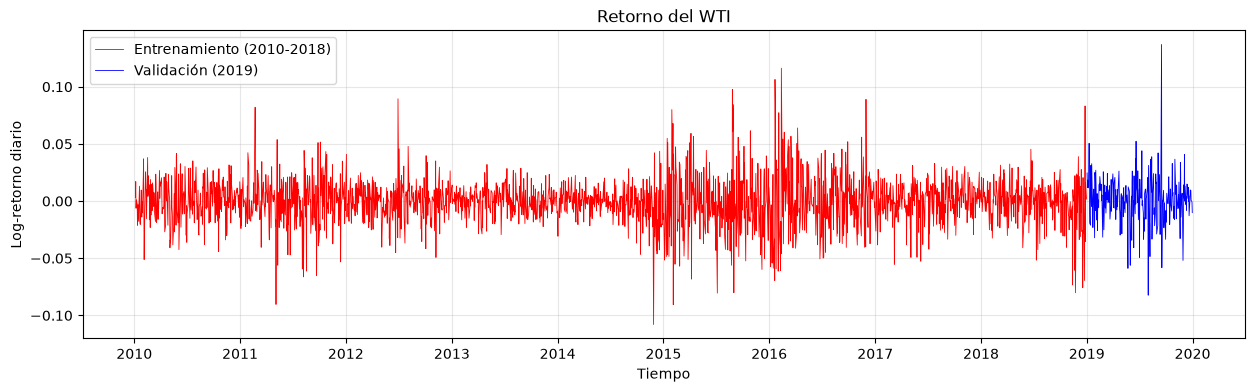

In [4]:
fig, ax = plt.subplots(figsize=(15, 4))
_ = ax.plot(y_train, color="r", lw=0.6, label="Entrenamiento (2010-2018)")
_ = ax.plot(y_val, color="b", lw=0.6, label="Validación (2019)")
_ = ax.set_xlabel("Tiempo"); ax.set_ylabel("Log-retorno diario")
_ = ax.set_title("Retorno del WTI"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

## 2. Validación cruzada de ventana expansiva (solo train)

La validación cruzada se realiza únicamente dentro del periodo de entrenamiento (2010-2018, 2.259 retornos del WTI), dividido en 4 pliegues. Cada pliegue entrena con todos los datos desde el inicio y valida con el tramo inmediatamente posterior, de modo que **nunca se usa información futura para predecir el pasado**. El año 2019 (validación) y el test no intervienen.

| Pliegue | Observaciones de entrenamiento | Observaciones de validación | Periodo de validación (aprox.) |
|---|---|---|---|
| 1 | 455 | 451 | finales de 2011 – mediados de 2013 |
| 2 | 907 | 451 | mediados de 2013 – mediados de 2015 |
| 3 | 1.359 | 451 | mediados de 2015 – inicios de 2017 |
| 4 | 1.811 | 448 | inicios de 2017 – diciembre de 2018 |

La ventana de entrenamiento crece en cada pliegue, mientras que los tramos de validación son consecutivos y no se solapan entre sí. Los primeros 455 retornos (hasta finales de 2011) solo se usan para entrenar. En el pliegue 4, la validación tiene 448 observaciones y no 451, porque el tramo llega al final de train.



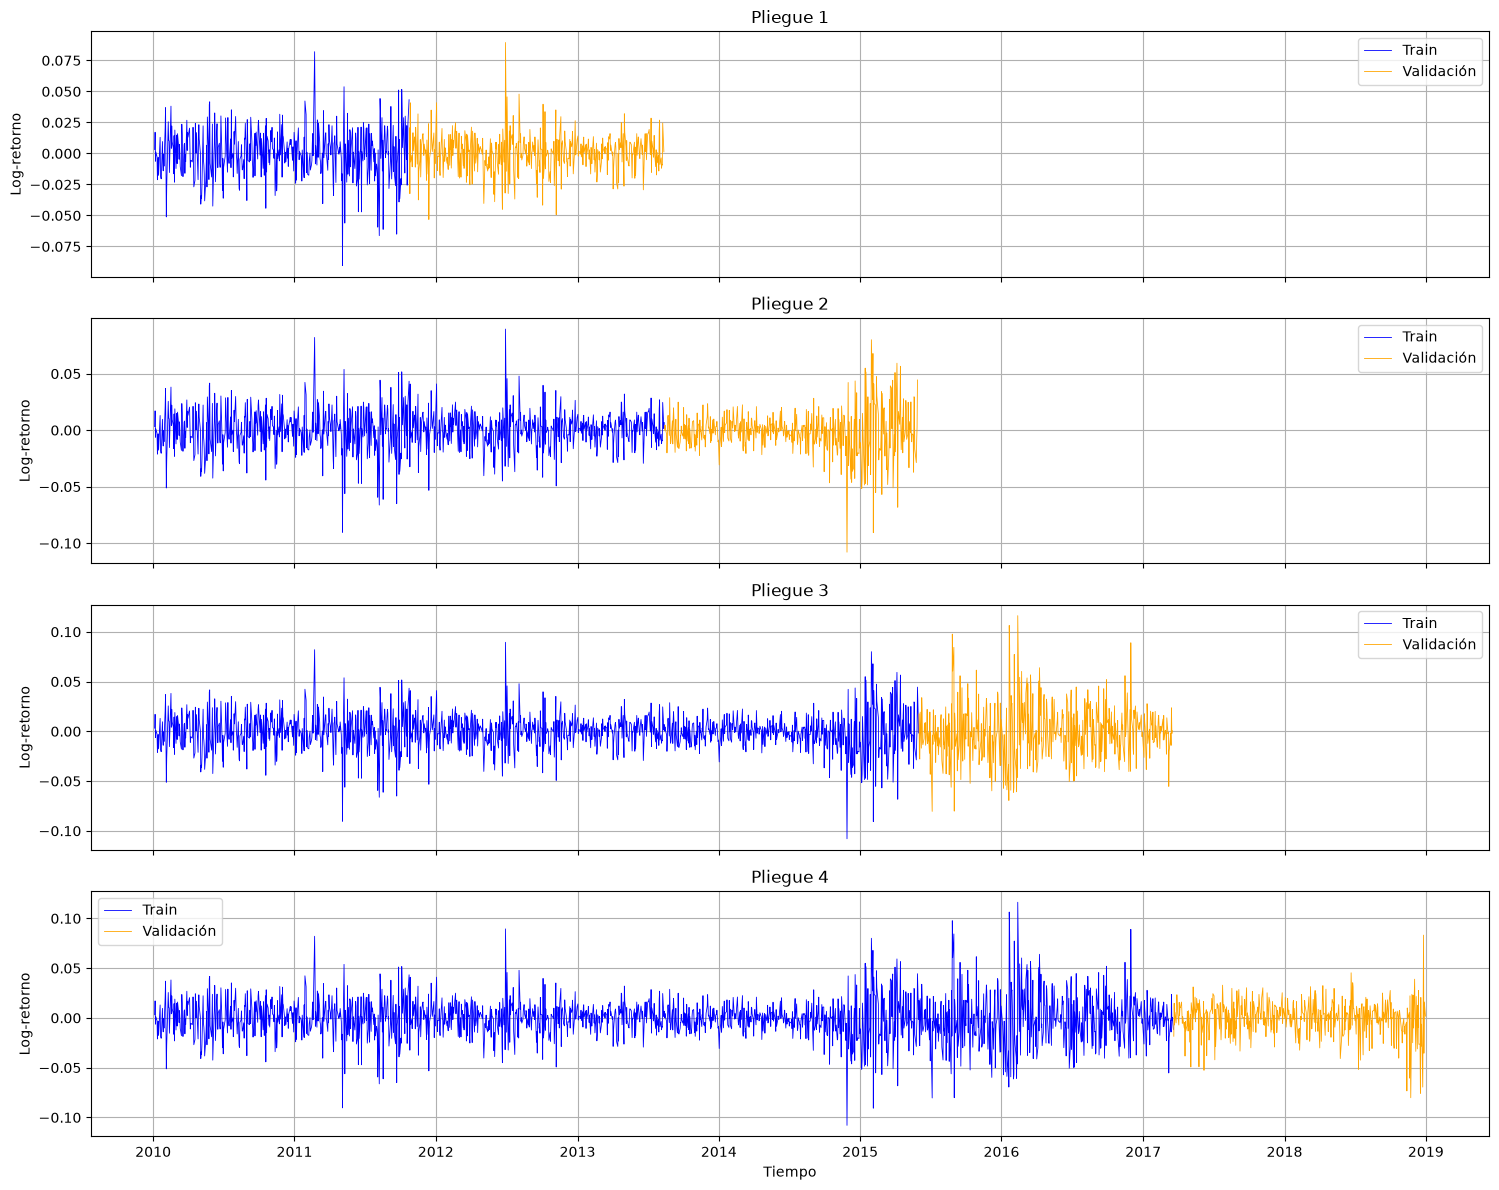

In [5]:
n_splits = 4
data_train_lst, data_validation_lst = K_fold(y_train, n_splits)
n_splits = len(data_train_lst)

fig, axs = plt.subplots(n_splits, 1, figsize=(15, 3 * n_splits), sharex=True)
for i in range(n_splits):
    axs[i].plot(data_train_lst[i], label="Train", color="blue", lw=0.6)
    axs[i].plot(data_validation_lst[i], label="Validación", color="orange", lw=0.6)
    axs[i].set_title(f"Pliegue {i + 1}")
    axs[i].set_ylabel("Log-retorno")
    axs[i].legend(); axs[i].grid(True)
plt.xlabel("Tiempo")
plt.tight_layout()
plt.show()

**Régimen de volatilidad en cada tramo de validación**
- **Pliegue 1:** volatilidad moderada, con una amplitud típica de ≈ ±0,05 y un pico cercano a +0,09.
- **Pliegue 2:** comienza muy tranquilo (2013-2014, retornos de ±0,02 aproximadamente) y termina con el inicio de la caída del petróleo, con oscilaciones que alcanzan ≈ ±0,1.
- **Pliegue 3:** es el tramo más volátil, con movimientos frecuentes entre −0,1 y +0,1 a lo largo de 2015-2016, durante el colapso de los precios.
- **Pliegue 4:** vuelve a una volatilidad moderada en 2017-2018, con retornos más pequeños y un repunte hacia finales de 2018.

**Implicaciones**
1. Los tramos de validación no son homogéneos: tienen niveles de volatilidad muy distintos, por lo que el RMSE de cada pliegue no es comparable en magnitud. Los pliegues 2 y 3, con mayor volatilidad, tendrán errores más altos que el 1 y el 4.
2. En el pliegue 1 el modelo se estima con solo 455 observaciones (≈ 1,8 años), por lo que sus coeficientes son los menos precisos. En los siguientes, la estimación mejora al disponer de más datos.
3. El RMSE medio entre pliegues, que se usa para elegir K, mezcla estos regímenes, por lo que debe interpretarse como un promedio entre periodos de calma y de alta volatilidad. Para valorar el modelo, la comparación relevante es contra el pronóstico "cero" en esos mismos pliegues.

## 3. Ventanas, ecuación normal y RMSE en un pliegue (K = 1, H = 1)

In [6]:
steps_back = 1
steps_ahead = 1
X_train, Y_train = create_sequences(data_train_lst[0], steps_back, steps_ahead)
X_val, Y_val = create_sequences(data_validation_lst[0], steps_back, steps_ahead)
print(X_train.shape, Y_train.shape, X_val.shape, Y_val.shape)

(454, 1) (454, 1) (450, 1) (450, 1)


In [7]:
W_hat = normal_equation(X_train, Y_train)
W_hat       # fila 0: intercepto; resto: peso de cada retorno rezagado

array([[0.00023314],
       [0.05826129]])

In [8]:
Y_hat_train = predict(X_train, W_hat)
Y_hat_val = predict(X_val, W_hat)

rmse_train = calculate_rmse(Y_train, Y_hat_train)
rmse_val = calculate_rmse(Y_val, Y_hat_val)
rmse_cero = calculate_rmse(Y_val, np.zeros_like(Y_val))     # referencia: predecir siempre 0
print(f"RMSE train pliegue 1:       {rmse_train:.6f}")
print(f"RMSE validación pliegue 1:  {rmse_val:.6f}")
print(f"RMSE 'cero' en validación:  {rmse_cero:.6f}")

RMSE train pliegue 1:       0.019953
RMSE validación pliegue 1:  0.015285
RMSE 'cero' en validación:  0.015154


| Medida | RMSE |
|---|---|
| Entrenamiento (pliegue 1) | 0,019953 |
| Validación (pliegue 1) | 0,015285 |
| Pronóstico "cero" en validación | 0,015154 |

El error se expresa en unidades de log-retorno diario, por lo que un RMSE de 0,0153 equivale a un error típico de ≈ 1,5 puntos porcentuales por día.

1. **El modelo no supera al pronóstico "cero".** En validación, el RMSE del modelo (0,015285) es 0,9 % mayor que el de predecir siempre un retorno nulo (0,015154), lo que equivale a un R² fuera de muestra de ≈ −1,7 %. Con retornos diarios, la regresión lineal sobre el retorno del día anterior no aporta capacidad predictiva.
2. **El coeficiente estimado es mínimo.** W = [0,00023; 0,058]: un retorno de +1 % el día anterior predice solo +0,058 % al día siguiente, además de un intercepto casi nulo. Es coherente con la autocorrelación débil observada en el EDA y no tiene relevancia económica.
3. **El RMSE de validación es menor que el de entrenamiento** (0,0153 frente a 0,0200). Esto no indica ausencia de sobreajuste, sino que los dos tramos tienen distinta volatilidad: el entrenamiento del pliegue 1 (2010-2011) incluye episodios más agitados que la validación (finales de 2011 – mediados de 2013), y el RMSE crece con la dispersión de los datos.
4. **Un solo pliegue no es concluyente.** Estos resultados corresponden al primer pliegue, que se entrena con solo 455 observaciones. La elección de K se hace con el promedio de los cuatro pliegues (sección 4).

## 4. Elección de K por validación cruzada (solo train)

H es el horizonte de predicción y se fija uno para elegir K.
Para retornos diarios la comparación relevante es contra el pronóstico "cero".

El K con menor RMSE de validación es 3 (RMSE: 0.020209)


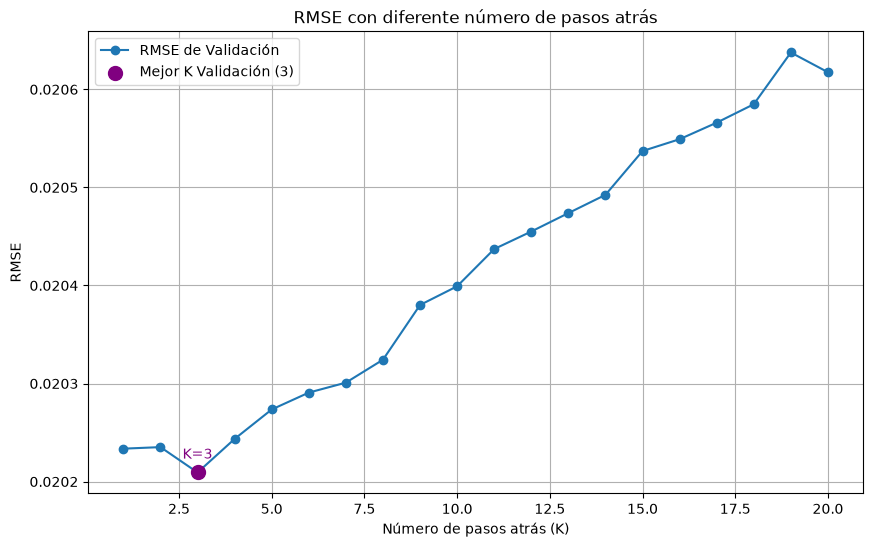

RMSE 'cero' (promedio de los pliegues): 0.020241


In [9]:
H = 1                       # horizonte; cambiar para otro valor de cfg.H_GRID
K_values = cfg.k_grid      # 1..20

best_k, rmse_tr_k, rmse_va_k = RMSE_CV_search_K(
    k_values=K_values, steps_ahead=H, training_dataset=y_train, n_splits=n_splits, plot="Validation")
print(f"RMSE 'cero' (promedio de los pliegues): {RMSE_CV_referencia(H, y_train, n_splits):.6f}")

La curva muestra el RMSE de validación promedio de los 4 pliegues para K entre 1 y 20 rezagos. El mínimo se alcanza en **K = 3** (RMSE = 0,020209).

1. **Las diferencias entre K son pequeñas.** El eje vertical abarca solo de 0,0202 a 0,0206, es decir, una variación total de ≈ 2 %. Entre K = 1 y K = 4 el RMSE va de 0,020209 a 0,020244, una diferencia menor a 0,2 %, por lo que esos cuatro valores son prácticamente equivalentes.
2. **A partir de K ≈ 5 el error crece de forma casi sostenida,** hasta ≈ 0,0206 en K = 19-20. Agregar rezagos empeora la predicción fuera de muestra, mientras que el RMSE de entrenamiento apenas cambia (de 0,0193 a 0,0193), lo que indica que los rezagos adicionales ajustan ruido y no información útil (sobreajuste).
3. **El modelo apenas supera al pronóstico "cero".** El RMSE de referencia es 0,020241, de modo que K = 3 lo mejora en 0,16 % (R² fuera de muestra ≈ +0,3 %), una mejora sin relevancia práctica. Para K ≥ 5 el modelo queda peor que predecir siempre cero.
4. **Conclusión:** el retorno diario del WTI casi no tiene componente lineal predecible a partir de sus propios rezagos. Se selecciona K = 3 por ser el mínimo de la validación cruzada, aunque su ventaja sobre K = 1 no es estadísticamente distinguible. Este modelo funciona como referencia (piso) que los modelos posteriores deben superar.

In [10]:
pd.DataFrame({"K": K_values, "RMSE_train_cv": rmse_tr_k, "RMSE_val_cv": rmse_va_k}).set_index("K").round(6).T

K,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
RMSE_train_cv,0.019304,0.019298,0.019300,0.019305,0.019308,0.019303,0.019307,0.019306,0.019289,0.019285,0.019283,0.019281,0.019275,0.019280,0.019270,0.019264,0.019268,0.019267,0.019241,0.019192
RMSE_val_cv,0.020234,0.020235,0.020209,0.020244,0.020274,0.020291,0.020301,0.020324,0.020380,0.020399,0.020437,0.020455,0.020474,0.020492,0.020537,0.020549,0.020566,0.020585,0.020638,0.020617


In [11]:
# Mejor K para cada horizonte propuesto (solo con train)
filas = []
for h in cfg.h_grid:
    k_h, _, va_h = RMSE_CV_search_K(K_values, h, y_train, n_splits, plot=None, verbose=False)
    filas.append({"H": h, "mejor_K": k_h, "RMSE_val_cv": min(va_h),
                  "RMSE_cero_cv": RMSE_CV_referencia(h, y_train, n_splits)})
pd.DataFrame(filas).set_index("H").round(6)

,mejor_K,RMSE_val_cv,RMSE_cero_cv
H,,,
1,3,0.020209,0.020241
5,1,0.020222,0.020213
10,1,0.020161,0.020144
21,1,0.020148,0.020128
63,1,0.020106,0.020081


El RMSE "cero" corresponde al error de un pronóstico ingenuo que predice un retorno nulo en todos los días (equivalente a suponer que el precio de mañana es igual al de hoy, es decir, un paseo aleatorio sin deriva). Se usa como referencia mínima: un modelo solo aporta capacidad predictiva si su RMSE es menor que el de esta regla. El $R²_{OS} = 1 − (RMSE_{modelo} / RMSE_{cero})²$ mide esa mejora relativa.

## 5. Validación (2019): modelo ajustado con todo train

Se ajusta W con **todo train** y el K elegido, y se evalúa en 2019. Las primeras K entradas de 2019 se toman del final de train
(`con_prefijo`), de modo que cada predicción de 2019 tiene sus K datos de entrada. **No se vuelve a elegir K con esto.**

In [12]:
X_tr, Y_tr = create_sequences(y_train, best_k, H)
W_final = normal_equation(X_tr, Y_tr)
mu_train = y_train.mean()

rmse_tr = calculate_rmse(Y_tr, predict(X_tr, W_final))
res_val = evaluar_segmento(y_train, y_val, W_final, best_k, H, mu_train)

print(f"K = {best_k}, H = {H}")
print(f"RMSE train:                  {rmse_tr:.6f}")
print(f"RMSE validación (modelo):    {res_val['RMSE_modelo']:.6f}")
print(f"RMSE validación (cero):      {res_val['RMSE_cero']:.6f}")
print(f"RMSE validación (media tr.): {res_val['RMSE_media_train']:.6f}")
print(f"ventanas válidas: {res_val['n_ventanas']}  |  descartadas por NaN: {res_val['n_descartadas']}")

K = 3, H = 1
RMSE train:                  0.020539
RMSE validación (modelo):    0.021289
RMSE validación (cero):      0.021267
RMSE validación (media tr.): 0.021283
ventanas válidas: 252  |  descartadas por NaN: 0


Con K = 3 y H = 1, el modelo ajustado con todo train obtiene en 2019 un RMSE de 0,021289, frente a 0,021267 del pronóstico "cero" y 0,021283 de la media de train. El R² fuera de muestra respecto al "cero" es ≈ −0,2 %: el modelo no mejora la referencia más simple, y queda prácticamente igual a ella (diferencia de 0,1 %). El RMSE de validación (0,0213) es similar al de entrenamiento (0,0205), lo que no indica sobreajuste; sencillamente el modelo tiene muy poca capacidad predictiva que pueda sobreajustarse.

Los coeficientes estimados son W = [−0,0003; −0,0294; +0,0335; −0,0674], donde el primero es el intercepto y los demás corresponden a los retornos de t−3, t−2 y t−1 (en ese orden). Todos son pequeños. El del día anterior (−0,067) es coherente con la autocorrelación de primer orden ligeramente negativa del EDA (≈ −0,07), y equivale a que un retorno de +1 % ayer predice ≈ −0,07 % hoy.

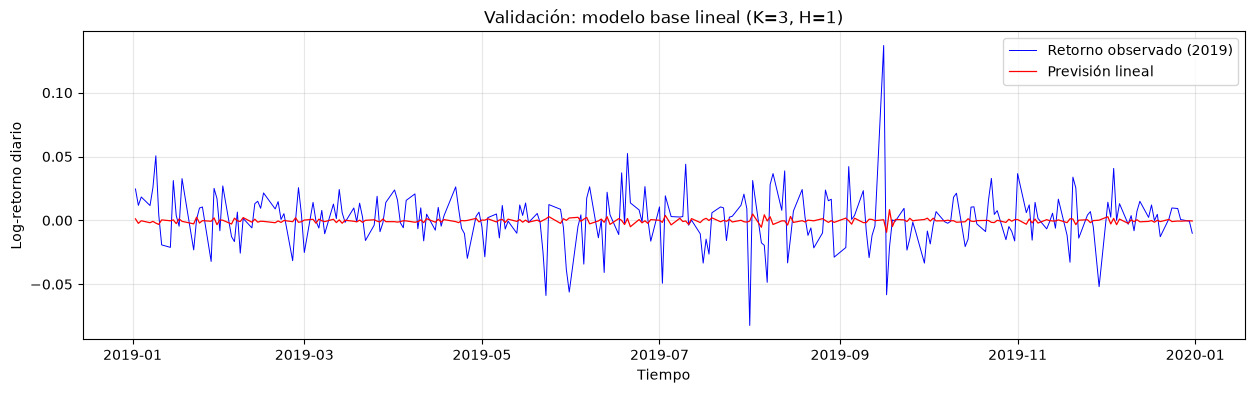

In [13]:
pred_val = reconstruir_vector(res_val["Y_hat"], y_val.index)

fig, ax = plt.subplots(figsize=(15, 4))
_ = ax.plot(y_val, color="b", lw=0.7, label="Retorno observado (2019)")
_ = ax.plot(pred_val, color="r", lw=0.9, label="Previsión lineal")
_ = ax.set_xlabel("Tiempo"); ax.set_ylabel("Log-retorno diario")
_ = ax.set_title(f"Validación: modelo base lineal (K={best_k}, H={H})"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

En 2019 los retornos observados oscilan entre ≈ ±0,05, con un pico excepcional de ≈ +0,14 hacia mediados de septiembre y una caída de ≈ −0,08 a comienzos de agosto. La predicción (roja) se mantiene prácticamente plana alrededor de cero, con valores del orden de ±0,005, y no anticipa ninguno de los movimientos grandes ni su signo. El modelo se comporta, en la práctica, como el pronóstico "cero" con ligeras oscilaciones.

## 6. Test (2020 en adelante)

A partir de aquí se usa el test, con el modelo **ya fijado** (K y W de la sección 5). El prefijo de entrada de la primera predicción
de 2020 son los últimos K días de 2019. En el WTI faltan los retornos del 20 y 21/04/2020 (precio negativo): las ventanas que los
contienen como entrada o como salida se descartan del RMSE y se cuentan aparte.

In [14]:
y_test = cargar("retornos", "test", permitir_test=True)[cfg.target]
print("test:", y_test.index.min().date(), "->", y_test.index.max().date(), len(y_test), "| nulos:", y_test.isna().sum())
print("fechas sin retorno:", [d.date() for d in y_test.index[y_test.isna()]])

test: 2020-01-02 -> 2026-10-20 1709 | nulos: 2
fechas sin retorno: [datetime.date(2020, 4, 20), datetime.date(2020, 4, 21)]


In [15]:
res_test = evaluar_segmento(y_val, y_test, W_final, best_k, H, mu_train)

print(f"RMSE test (modelo):    {res_test['RMSE_modelo']:.6f}")
print(f"RMSE test (cero):      {res_test['RMSE_cero']:.6f}")
print(f"RMSE test (media tr.): {res_test['RMSE_media_train']:.6f}")
print(f"ventanas válidas: {res_test['n_ventanas']}  |  descartadas por NaN: {res_test['n_descartadas']}")

RMSE test (modelo):    0.031595
RMSE test (cero):      0.031492
RMSE test (media tr.): 0.031496
ventanas válidas: 1704  |  descartadas por NaN: 5


En el test (2020-2026) el RMSE del modelo es 0,031595, frente a 0,031492 del pronóstico "cero" y 0,031496 de la media de train. El modelo queda un 0,33 % por encima de "cero" (R² fuera de muestra ≈ −0,66 %), es decir, no supera a la referencia. Se evaluaron 1.704 ventanas válidas; se descartaron 5: los retornos del 20 y 21/04/2020 (que no existen por el precio negativo) y las predicciones de los tres días siguientes (22, 23 y 24/04), que usan esos retornos faltantes como entrada con K = 3.

In [16]:
# RMSE por sub-ventana del test (cfg.VENTANAS_TEST): COVID, recuperación, 2022, calma, 2026
rmse_por_ventana(res_test, cfg.ventanas_test, mu_train).round(6)

,ventanas_validas,descartadas_por_NaN,RMSE_modelo,RMSE_cero,RMSE_media_train
ventana,,,,,
covid,248,5,0.054504,0.054423,0.054420
rec_2021,252,0,0.022399,0.022405,0.022426
rob_2022,251,0,0.030704,0.030466,0.030469
calma_23_25,752,0,0.019920,0.019870,0.019866
rec_2026,201,0,0.038814,0.038570,0.038590


| Ventana | RMSE modelo | RMSE "cero" | Modelo frente a "cero" |
|---|---|---|---|
| covid | 0,0545 | 0,0544 | +0,15 % |
| rec_2021 | 0,0224 | 0,0224 | −0,03 % |
| rob_2022 | 0,0307 | 0,0305 | +0,78 % |
| calma_23_25 | 0,0199 | 0,0199 | +0,25 % |
| rec_2026 | 0,0388 | 0,0386 | +0,63 % |

1. **El nivel del error depende del régimen, no del modelo.** El RMSE del COVID (0,0545) es 2,7 veces el de la ventana tranquila 2023-2025 (0,0199), pero el del pronóstico "cero" varía de la misma forma. El error de ambos es esencialmente la volatilidad de cada periodo.
2. **El modelo no supera a "cero" de forma consistente.** Solo en 2021 queda marginalmente por debajo (−0,03 %), diferencia sin relevancia; en las otras cuatro ventanas queda entre 0,15 % y 0,78 % por encima, con la mayor desventaja en 2022 y 2026, periodos de mayor volatilidad relativa.
3. **El COVID no revela un fallo especial del modelo.** Un modelo lineal sobre los propios rezagos no puede anticipar un choque de esa magnitud, y el pronóstico "cero" tampoco. Este resultado fija el piso con el que se compararán los modelos con memoria de volatilidad, las exógenas y los generativos.

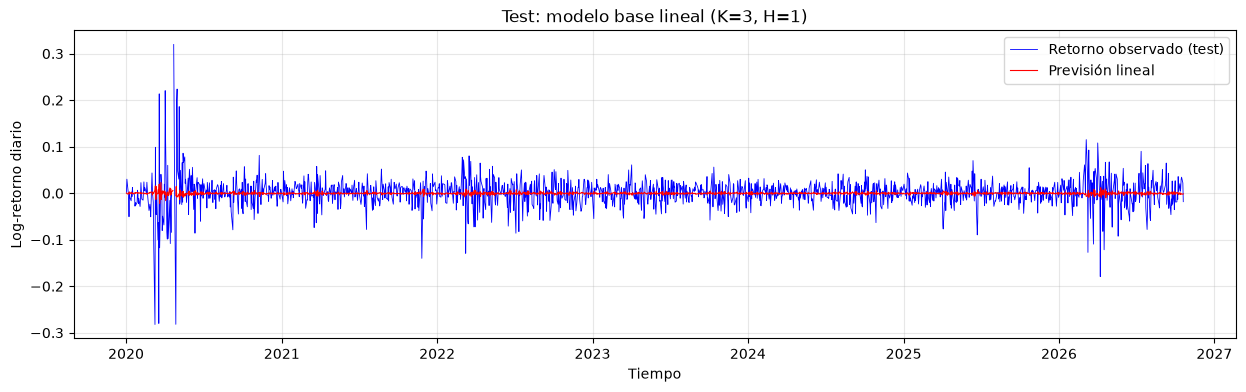

In [17]:
pred_test = reconstruir_vector(res_test["Y_hat"], y_test.index)

fig, ax = plt.subplots(figsize=(15, 4))
_ = ax.plot(y_test, color="b", lw=0.6, label="Retorno observado (test)")
_ = ax.plot(pred_test, color="r", lw=0.8, label="Previsión lineal")
_ = ax.set_xlabel("Tiempo"); ax.set_ylabel("Log-retorno diario")
_ = ax.set_title(f"Test: modelo base lineal (K={best_k}, H={H})"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

La predicción (roja) permanece cerca de cero durante todo el test, mientras que los retornos observados alcanzan ±0,3 en marzo-abril de 2020 y presentan episodios de mayor dispersión a finales de 2021, a comienzos de 2022 y en 2026 (hasta ≈ −0,18). La previsión se amplía ligeramente en esos mismos periodos, porque es una combinación lineal de los últimos retornos y hereda su magnitud, pero con coeficientes tan pequeños que su amplitud es un orden de magnitud menor que la de los datos y no acierta el signo de los movimientos grandes.

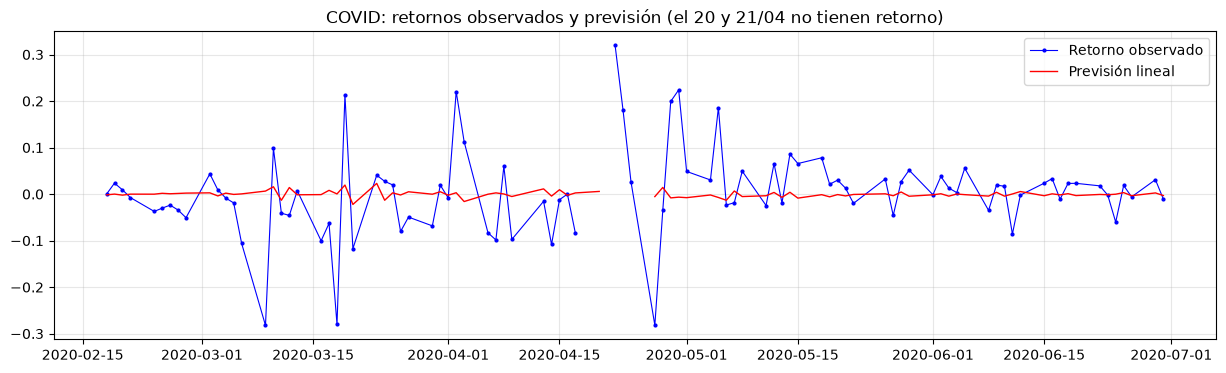

In [18]:
# Zoom en el evento COVID (feb-jun 2020)
a, b = "2020-02-15", "2020-06-30"
fig, ax = plt.subplots(figsize=(15, 4))
_ = ax.plot(y_test.loc[a:b], color="b", marker="o", ms=2, lw=0.8, label="Retorno observado")
_ = ax.plot(pred_test.loc[a:b], color="r", lw=1.0, label="Previsión lineal")
_ = ax.set_title("COVID: retornos observados y previsión (el 20 y 21/04 no tienen retorno)"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

Entre febrero y junio de 2020 los retornos observados oscilan entre ≈ −0,28 y +0,32, con varios movimientos diarios de más de 20 puntos porcentuales, mientras que la previsión se mueve en un rango de ≈ ±0,02. La línea roja se interrumpe del 20 al 24 de abril: el 20 y 21 no tienen retorno observado (precio negativo del WTI) y los tres días siguientes no pueden predecirse porque su entrada incluye esos retornos faltantes. 

La línea roja se interrumpe del 20 al 24 de abril. El 20/04 el precio del WTI es negativo (−37,63) y el 21/04, aunque el precio ya es positivo, el precio previo no lo es; en ambos casos el log-retorno no está definido, por lo que no hay retorno observado. Los tres días siguientes (22, 23 y 24) sí tienen retorno observado, pero no pueden predecirse porque sus tres retornos de entrada (K = 3) incluyen al menos uno de esos valores faltantes.

El mayor movimiento del evento, el desplome del 20/04, queda fuera de la evaluación diaria y por eso se evaluará aparte con el log-retorno acumulado entre el 17 y el 21/04/2020 (−0,60).

In [19]:
# Pronóstico de los H días siguientes al último dato (como en el cuaderno original)
pronostico_futuro(y_test.dropna(), W_final, best_k)

2026-10-21    0.000666
Freq: B, Name: Predicho, dtype: float64

In [20]:
resumen = pd.DataFrame({
    "RMSE_modelo": [res_val["RMSE_modelo"], res_test["RMSE_modelo"]],
    "RMSE_cero": [res_val["RMSE_cero"], res_test["RMSE_cero"]],
    "RMSE_media_train": [res_val["RMSE_media_train"], res_test["RMSE_media_train"]],
}, index=["validación 2019", "test 2020-2026"])
resumen["R2_OS_vs_cero"] = [r2_fuera_de_muestra(a, b) for a, b in zip(resumen["RMSE_modelo"], resumen["RMSE_cero"])]
print("Coeficientes W (fila 0: intercepto; luego, rezagos 1..K):", np.round(W_final.ravel(), 4))
resumen.round(6)

Coeficientes W (fila 0: intercepto; luego, rezagos 1..K): [-0.0003 -0.0294  0.0335 -0.0674]


,RMSE_modelo,RMSE_cero,RMSE_media_train,R2_OS_vs_cero
validación 2019,0.021289,0.021267,0.021283,-0.002065
test 2020-2026,0.031595,0.031492,0.031496,-0.006551


| | RMSE modelo | RMSE "cero" | R² fuera de muestra |
|---|---|---|---|
| Validación 2019 | 0,021289 | 0,021267 | −0,21 % |
| Test 2020-2026 | 0,031595 | 0,031492 | −0,66 % |

El R² fuera de muestra es negativo y cercano a cero en ambos tramos: el modelo lineal sobre rezagos no mejora el pronóstico "cero", y la diferencia es muy pequeña.

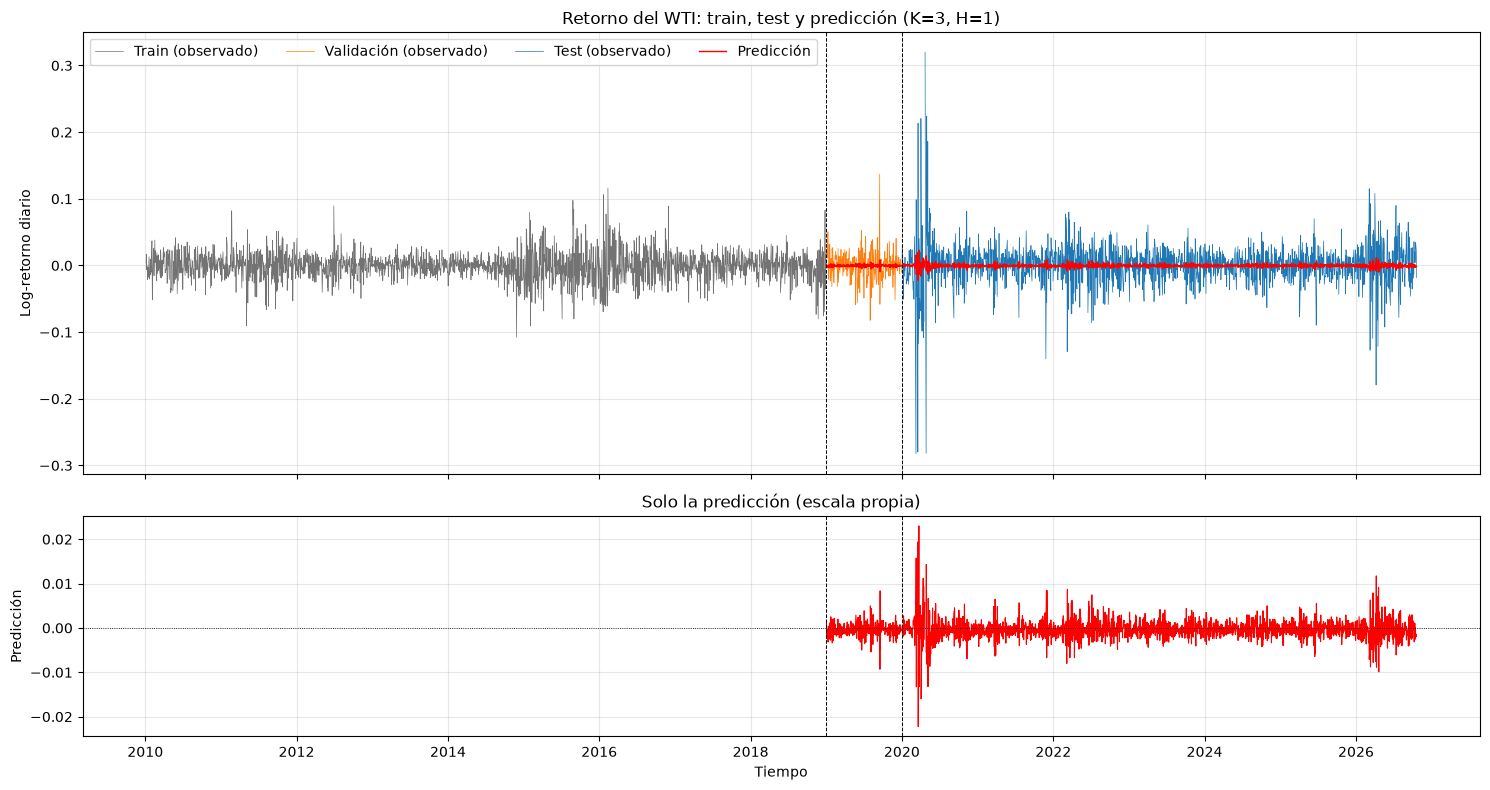

In [21]:
graficar_train_test_prediccion(y_train, y_val, y_test, pred_val, pred_test, titulo=f"(K={best_k}, H={H})")

El  gráfico reúne train, validación, test y la predicción. Se aprecia el cambio de régimen de volatilidad entre tramos: calma relativa en train y 2019, y episodios mucho más extremos en el test. En el panel inferior, con escala propia, la predicción varía como máximo ≈ ±0,02 (en 2020) y su amplitud sigue el ritmo de la volatilidad.

La predicción del modelo lineal no captura los picos del test (retornos de hasta ±0,3 en el COVID frente a previsiones de ±0,02 como máximo), lo cual es esperable: los coeficientes estimados son muy pequeños y los choques extremos no son predecibles a partir de los retornos pasados. Lo que sí es predecible es la magnitud de los movimientos, que tiende a agruparse en el tiempo (ARCH-LM y Ljung-Box de r² significativos), por lo que la capacidad de anticipar episodios extremos debe buscarse en modelos de volatilidad condicional y en salidas probabilísticas, no en la predicción puntual del retorno.

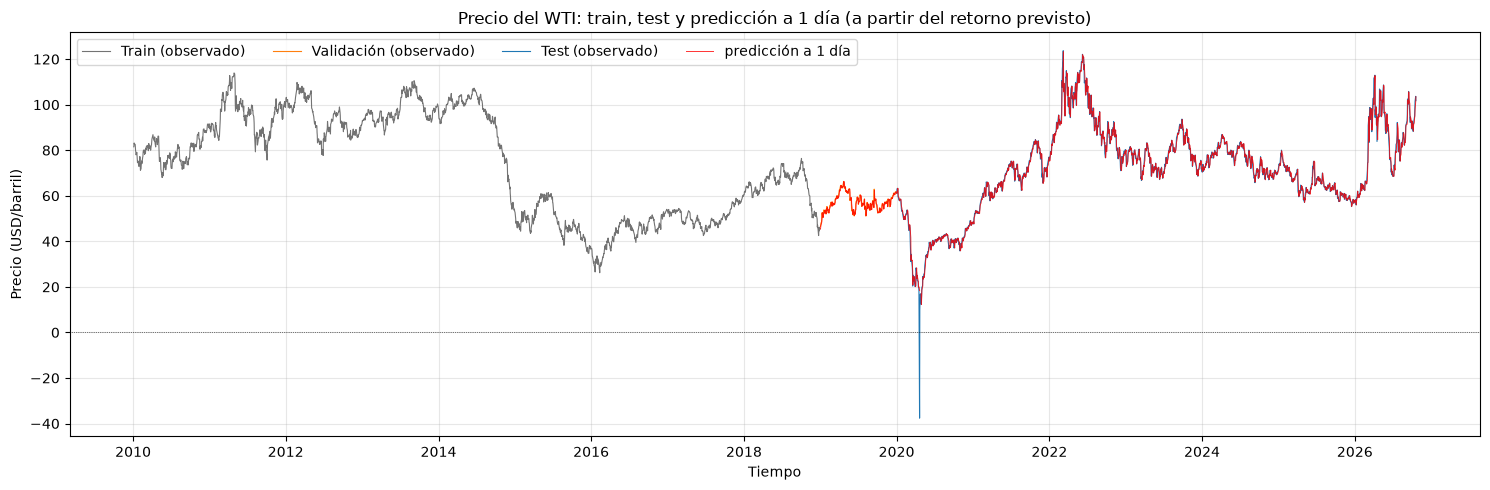

In [22]:
# Precio del WTI con la previsión a 1 día (solo H = 1). El precio negativo del 20/04/2020 se ve en el gráfico.
px_train = cargar("precios", "train")[cfg.target]
px_val = cargar("precios", "val")[cfg.target]
px_test = cargar("precios", "test", permitir_test=True)[cfg.target]
graficar_precio_prediccion(px_train, px_val, px_test, pred_val, pred_test, H=H)

El gráfico muestra el precio del WTI (nivel) junto con la prediccióm a 1 día, obtenida como $P̂ₜ = Pₜ₋₁·exp(r̂ₜ)$, donde $r̂ₜ$ es el retorno previsto por el modelo lineal. La predicción sigue de cerca al precio observado, pero esto se debe en gran parte a que se construye a partir del precio del día anterior: con retornos previstos de magnitud muy pequeña, y la cercanía visual no implica capacidad predictiva. La comparación válida es la del RMSE en retornos frente al pronóstico cero $(R²_OS ≈ −0,66 %)$. No se genera predicciòn para el 20–24/04/2020, porque el precio negativo impide calcular el retorno logarítmico.